# Portfolio construction and backtest

In [1]:
import sys

sys.path.insert(0, "..")
import pandas as pd
import config

P = config.PATHS
pd.read_csv(P.tables / "summary_metrics.csv", index_col=0)

,AnnReturn,AnnVol,Sharpe,Sortino,MaxDrawdown,Calmar,CVaR5,AnnTurnover,Months
BL_ML_Regime,0.076545,0.074857,0.844414,1.356453,-0.162349,0.471487,-0.040376,2.363050,211.0
BL_ML_Regime_IC,0.073783,0.070029,0.860644,1.370637,-0.132485,0.556913,-0.037505,1.407590,211.0
BL_ML_NoRegime,0.094143,0.094067,0.862048,1.391434,-0.228490,0.412021,-0.055405,2.191540,211.0
BL_ML_Raw_Regime,0.070756,0.080175,0.725196,1.118635,-0.167073,0.423505,-0.048313,4.004903,211.0
BL_HistMean_Regime,0.079595,0.073826,0.893913,1.457713,-0.153128,0.519792,-0.038948,1.342525,211.0
Market_Reference,0.103939,0.097418,0.926883,1.519080,-0.210603,0.493530,-0.055646,0.345936,211.0
Equal_Weight,0.094899,0.112512,0.743854,1.299958,-0.235862,0.402351,-0.058937,0.540171,211.0
Static_60_40,0.103733,0.091176,0.980462,1.595831,-0.205222,0.505469,-0.051941,0.265035,211.0
Inverse_Vol,0.066374,0.071303,0.748663,1.185394,-0.177275,0.374415,-0.041878,0.461058,211.0
MeanVariance_LW,0.059977,0.132818,0.402221,0.616532,-0.369744,0.162211,-0.081104,2.524840,211.0


In [2]:
pd.read_csv(P.tables / "significance.csv")

,strategy,benchmark,diff,ci_low,ci_high,p_value,n
0,BL_ML_Regime,BL_ML_Regime_IC,-0.016230,-0.134530,0.096322,0.789303,211
1,BL_ML_Regime,BL_ML_NoRegime,-0.017634,-0.153051,0.100655,0.791052,211
2,BL_ML_Regime,BL_ML_Raw_Regime,0.119218,-0.022519,0.272414,0.111722,211
3,BL_ML_Regime,BL_HistMean_Regime,-0.049499,-0.112300,0.011624,0.117721,211
4,BL_ML_Regime,Market_Reference,-0.082469,-0.253364,0.067722,0.324919,211
5,BL_ML_Regime,Equal_Weight,0.100560,-0.109761,0.337874,0.361660,211
6,BL_ML_Regime,Static_60_40,-0.136048,-0.378407,0.060228,0.230692,211
7,BL_ML_Regime,Inverse_Vol,0.095751,-0.144056,0.295659,0.381655,211
8,BL_ML_Regime,MeanVariance_LW,0.442193,0.141878,0.751348,0.004999,211
9,BL_ML_Regime,Regime_60_40,-0.135375,-0.374091,0.074314,0.237941,211


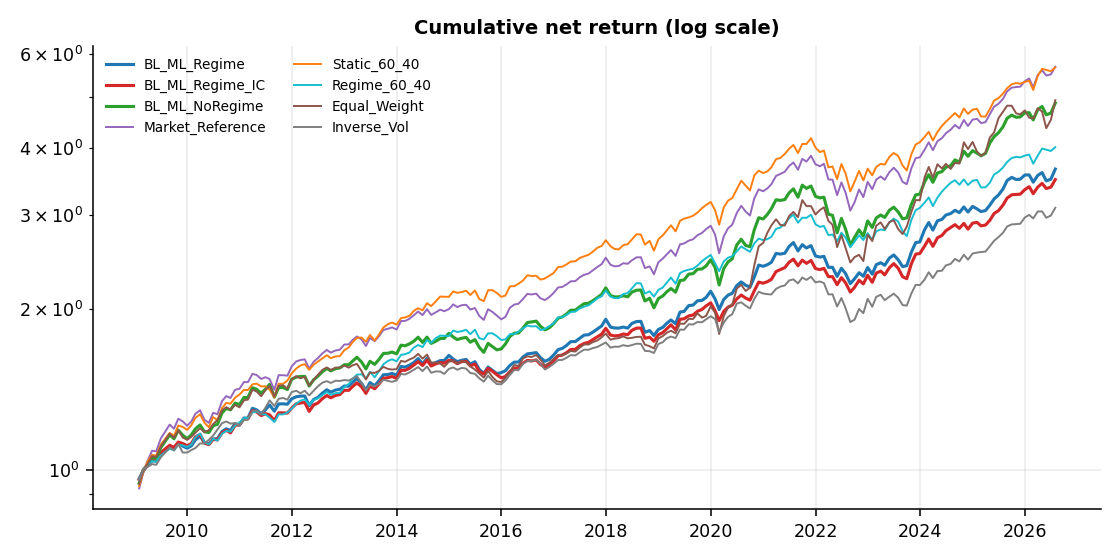

In [3]:
from IPython.display import Image

Image(str(P.figures / "07_cumulative_returns.png"))

In [4]:
pd.read_csv(P.tables / "regime_metrics.csv", index_col=[0, 1])

AnnReturn    AnnVol    Sharpe   Sortino  \
BL_ML_Regime       All        0.076545  0.074857  0.844414  1.356453   
                   Calm       0.071742  0.075426  0.757818  1.225245   
                   Stressed   0.086499  0.074148  1.020119  1.625733   
BL_ML_Regime_IC    All        0.073783  0.070029  0.860644  1.370637   
                   Calm       0.066557  0.070243  0.738971  1.158424   
                   Stressed   0.088806  0.069924  1.107706  1.831922   
BL_ML_NoRegime     All        0.094143  0.094067  0.862048  1.391434   
                   Calm       0.072222  0.075434  0.763751  1.236781   
                   Stressed   0.140674  0.123577  1.049153  1.682825   
BL_ML_Raw_Regime   All        0.070756  0.080175  0.725196  1.118635   
                   Calm       0.068879  0.084484  0.652386  1.011727   
                   Stressed   0.074630  0.071064  0.904606  1.384896   
BL_HistMean_Regime All        0.079595  0.073826  0.893913  1.457713   
                   Calm       0.073200  0.074377  0.786033  1.277304   
                   Stressed   0.092876  0.073092  1.114721  1.839798   
Market_Reference   All        0.103939  0.097418  0.926883  1.519080   
                   Calm       0.075984  0.074823  0.816134  1.288680   
                   Stressed   0.163775  0.131488  1.146670  1.913965   
Equal_Weight       All        0.094899  0.112512  0.743854  1.299958   
                   Calm       0.057008  0.094981  0.471497  0.806763   
                   Stressed   0.177207  0.140178  1.169160  2.055228   
Static_60_40       All        0.103733  0.091176  0.980462  1.595831   
                   Calm       0.080392  0.070113  0.922228  1.435876   
                   Stressed   0.153368  0.123258  1.140569  1.906032   
Inverse_Vol        All        0.066374  0.071303  0.748663  1.185394   
                   Calm       0.055294  0.060090  0.674895  1.087121   
                   Stressed   0.089546  0.090259  0.885495  1.381842   
MeanVariance_LW    All        0.059977  0.132818  0.402221  0.616532   
                   Calm       0.038848  0.114899  0.255875  0.366346   
                   Stressed   0.104822  0.163822  0.627872  1.042592   
Regime_60_40       All        0.082348  0.069463  0.979789  1.551506   
                   Calm       0.079598  0.070123  0.911538  1.415967   
                   Stressed   0.088031  0.068567  1.117040  1.861110   
Regime_Market      All        0.081244  0.074160  0.910349  1.456206   
                   Calm       0.075202  0.074840  0.806140  1.269599   
                   Stressed   0.093785  0.073171  1.124443  1.872131   

                             MaxDrawdown    Calmar     CVaR5  AnnTurnover  \
BL_ML_Regime       All         -0.162349  0.471487 -0.040376     2.363050   
                   Calm        -0.116168  0.617568 -0.037565     2.406987   
                   Stressed    -0.112403  0.769540 -0.042921     2.272630   
BL_ML_Regime_IC    All         -0.132485  0.556913 -0.037505     1.407590   
                   Calm        -0.102385  0.650070 -0.035660     1.226147   
                   Stressed    -0.097444  0.911358 -0.039000     1.780996   
BL_ML_NoRegime     All         -0.228490  0.412021 -0.055405     2.191540   
                   Calm        -0.115408  0.625801 -0.037537     1.955509   
                   Stressed    -0.190337  0.739079 -0.070750     2.677284   
BL_ML_Raw_Regime   All         -0.167073  0.423505 -0.048313     4.004903   
                   Calm        -0.112207  0.613856 -0.047778     4.315844   
                   Stressed    -0.112234  0.664944 -0.045940     3.364994   
BL_HistMean_Regime All         -0.153128  0.519792 -0.038948     1.342525   
                   Calm        -0.109076  0.671089 -0.036517     1.149277   
                   Stressed    -0.109151  0.850894 -0.040609     1.740224   
Market_Reference   All         -0.210603  0.493530 -0.055646     0.345936   
                   Calm        -0.105625  0.719375 -0.0

In [5]:
pd.read_csv(P.tables / "cost_sensitivity.csv", index_col=0)

,0bps,10bps,25bps,50bps
BL_ML_Regime,0.877241,0.844414,0.795222,0.713424
BL_ML_Regime_IC,0.881589,0.860644,0.829195,0.776733
BL_ML_NoRegime,0.886632,0.862048,0.825227,0.764031
BL_ML_Raw_Regime,0.775134,0.725196,0.650128,0.524712
BL_HistMean_Regime,0.912742,0.893913,0.865634,0.818432
Market_Reference,0.930855,0.926883,0.920921,0.910976
Equal_Weight,0.748848,0.743854,0.736358,0.723855
Static_60_40,0.983801,0.980462,0.975448,0.967074
Inverse_Vol,0.755557,0.748663,0.738318,0.721066
MeanVariance_LW,0.421113,0.402221,0.373841,0.326436
